# ShopNext | E-commerce A/B Test — End-to-End Product Analysis

**Portfolio case study · Python · Experimentation · Statistical inference**

**Business question:** Does a redesigned checkout increase purchase conversion without hurting revenue per user? Variant A is the existing checkout and B is the simplified redesign.

**Data provenance:** Fully **synthetic, simulated** user-level data created for educational and portfolio use. Results are **not** evidence of a real company's performance. We treat these observations as if they came from a completed experiment for analytical practice.

**Primary metric:** user conversion rate. **Secondary:** revenue per randomized user (RPU), average order value (AOV). **Unit:** unique user. **Significance:** two-sided α=0.05. **Decision rule:** evaluate the primary metric with a 95% CI; interpret secondary and diagnostic results separately. No pre-registered non-inferiority margin is supplied, so we do not claim proof of no revenue harm.

All results below are computed from the included CSVs, not hardcoded.

## 1. Load data and inspect quality

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower
from IPython.display import display, Markdown
SEED=42
ROOT=Path.cwd().resolve()
if not (ROOT/'data').exists():
    ROOT=ROOT.parent
raw=pd.read_csv(ROOT/'data'/'shopnext_experiment_raw.csv',parse_dates=['date'])
hyp=pd.read_csv(ROOT/'data'/'hypotheses.csv')
print('Raw rows:',len(raw),'Duplicate user IDs:',raw.user_id.duplicated().sum())
display(raw.head(),raw.isna().sum().to_frame('missing'))
assert not raw[['user_id','group','converted','revenue_kzt']].isna().any().any()
assert raw.group.isin(['A','B']).all()
assert raw.converted.isin([0,1]).all()
assert (raw.revenue_kzt>=0).all()
assert (raw.loc[raw.converted.eq(0),'revenue_kzt']==0).all()
print('Conflicting repeated user rows:', raw.groupby('user_id')[['group','converted','revenue_kzt']].nunique().gt(1).any(axis=1).sum())
df=raw.drop_duplicates('user_id',keep='first').copy()
assert df.user_id.is_unique
print('Analyzed unique users:',len(df))

Raw rows: 12012 Duplicate user IDs: 12


,user_id,date,group,segment,device,country,converted,revenue_kzt
0,110884,2026-09-16,A,returning,mobile,KZ,0,0
1,101125,2026-09-10,A,new,mobile,UZ,0,0
2,106075,2026-09-18,A,new,mobile,KZ,0,0
3,109577,2026-09-02,B,new,mobile,KZ,0,0
4,104157,2026-09-06,A,returning,desktop,KG,0,0


,missing
user_id,0
date,0
group,0
segment,0
device,0
country,0
converted,0
revenue_kzt,0


Conflicting repeated user rows: 0
Analyzed unique users: 12000


**Data-quality note.** The raw export includes duplicated user IDs. Inspect repeated records before deduplication; if conflicting rows exist, a real analyst must reconcile them against event timestamps/source systems instead of arbitrarily keeping the first. Here the retained synthetic record is the project-defined unit of analysis.

## 2. Product idea prioritization (ICE and RICE)

In [2]:
hyp['ICE']=hyp['impact']*hyp['confidence']/hyp['effort']
hyp['RICE']=hyp['reach']*hyp['impact']*hyp['confidence']/hyp['effort']
display(hyp.sort_values('RICE',ascending=False))

,hypothesis,reach,impact,confidence,effort,ICE,RICE
1,Show expected delivery date,7,8,7,6,9.333333,65.333333
2,Add customer reviews,6,6,7,5,8.400000,50.400000
0,Simplify checkout flow,8,7,8,9,6.222222,49.777778
3,Offer guest checkout,7,8,6,7,6.857143,48.000000
4,Improve payment messaging,5,7,6,6,7.000000,35.000000


**Interpretation:** These are hypothetical ordinal scores, not calibrated monetary outcomes. Ranking helps focus discovery, not establish causal impact.

## 3. Core business metrics

In [3]:
metrics=df.groupby('group').agg(users=('user_id','size'),buyers=('converted','sum'),revenue_kzt=('revenue_kzt','sum'))
metrics['conversion_rate']=metrics.buyers/metrics.users
metrics['rpu_kzt']=metrics.revenue_kzt/metrics.users
metrics['aov_kzt']=metrics.revenue_kzt/metrics.buyers
metrics=metrics.reindex(['A','B'])
display(metrics.round(3))
a,b=metrics.loc['A'],metrics.loc['B']
cr_diff=b.conversion_rate-a.conversion_rate
relative_lift=cr_diff/a.conversion_rate
print(f'Absolute conversion lift: {cr_diff:.3%} = {100*cr_diff:.2f} percentage points')
print(f'Relative conversion lift: {relative_lift:.2%}')

,users,buyers,revenue_kzt,conversion_rate,rpu_kzt,aov_kzt
group,,,,,,
A,6000,637,13382640,0.106,2230.440,21008.854
B,6000,645,12749235,0.108,2124.872,19766.256


Absolute conversion lift: 0.133% = 0.13 percentage points
Relative conversion lift: 1.26%


## 4. Distribution checks and outliers

Buyers: 1282; order-value median: 16,356 KZT; IQR upper fence: 43,921 KZT; above fence: 60


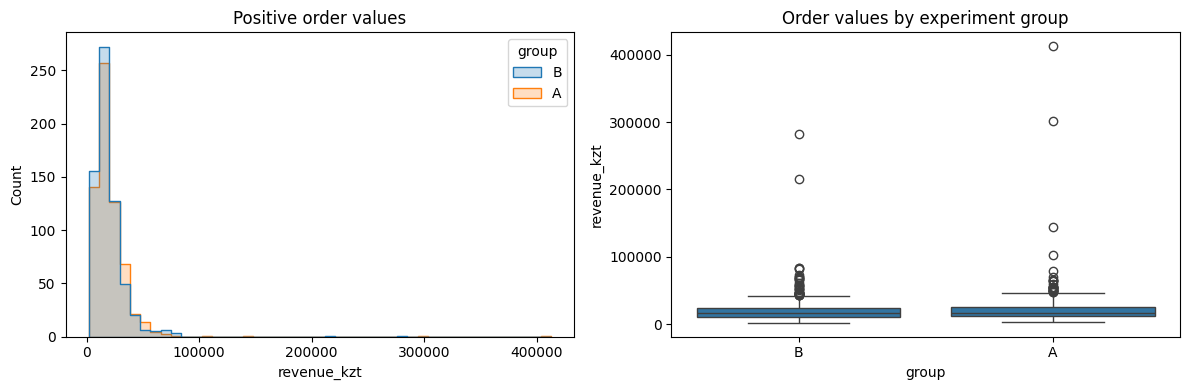

In [4]:
orders=df[df.converted.eq(1)].copy()
q1,q3=orders.revenue_kzt.quantile([.25,.75]); iqr=q3-q1; upper=q3+1.5*iqr
print(f'Buyers: {len(orders)}; order-value median: {orders.revenue_kzt.median():,.0f} KZT; IQR upper fence: {upper:,.0f} KZT; above fence: {(orders.revenue_kzt>upper).sum()}')
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=orders,x='revenue_kzt',hue='group',bins=45,element='step',ax=ax[0]);ax[0].set_title('Positive order values')
sns.boxplot(data=orders,x='group',y='revenue_kzt',ax=ax[1]);ax[1].set_title('Order values by experiment group')
fig.tight_layout();plt.savefig(ROOT/'images'/'order_value_distribution.png',dpi=160,bbox_inches='tight');plt.show()

**Caution:** High-value purchases may be genuine; removing them after seeing the result can bias a decision. Report full-data results as primary, with any trimming or winsorization as a labeled sensitivity analysis.

## 5. Validate allocation (sample ratio mismatch)

In [5]:
counts=metrics.users.values
chi2,srm_p=stats.chisquare(counts,f_exp=[counts.sum()/2]*2)
print(f'A/B counts: {counts.tolist()}; chi-square={chi2:.3f}; SRM p={srm_p:.5f}')
print('Allocation diagnostic:', 'unexpected difference—investigate assignment and logging' if srm_p<0.001 else 'no strong SRM evidence at diagnostic threshold 0.001')

A/B counts: [6000, 6000]; chi-square=0.000; SRM p=1.00000
Allocation diagnostic: no strong SRM evidence at diagnostic threshold 0.001


**Assumption:** planned allocation is 50/50. SRM evaluates counts, not whether groups are identical across all covariates. A non-significant SRM test is not proof that instrumentation is correct.

## 6. Primary inference: conversion-rate z-test and confidence intervals

A: conversion 10.62%; 95% Wilson CI [9.86%, 11.42%]
B: conversion 10.75%; 95% Wilson CI [9.99%, 11.56%]
B − A absolute effect: 0.13%; 95% Newcombe CI [-0.97%, 1.24%]; z=-0.236; p=0.81311


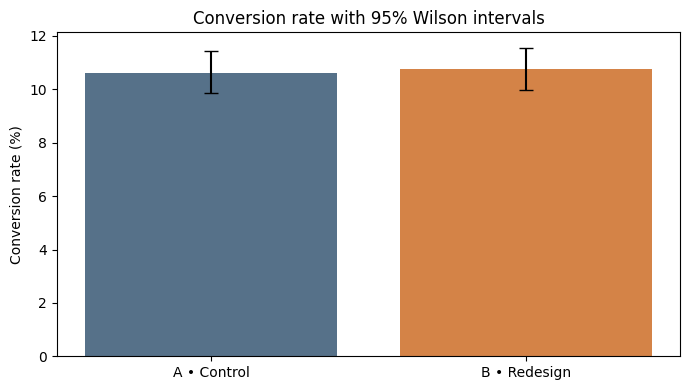

In [6]:
succ=metrics.buyers.to_numpy();nobs=metrics.users.to_numpy()
z_stat,p_cr=proportions_ztest(succ,nobs,alternative='two-sided')
ci_abs=confint_proportions_2indep(count1=int(succ[1]),nobs1=int(nobs[1]),count2=int(succ[0]),nobs2=int(nobs[0]),method='newcomb',compare='diff',alpha=.05)
for group in ['A','B']:
 m=metrics.loc[group];ci=proportion_confint(m.buyers,m.users,alpha=.05,method='wilson')
 print(f'{group}: conversion {m.conversion_rate:.2%}; 95% Wilson CI [{ci[0]:.2%}, {ci[1]:.2%}]')
print(f'B − A absolute effect: {cr_diff:.2%}; 95% Newcombe CI [{ci_abs[0]:.2%}, {ci_abs[1]:.2%}]; z={z_stat:.3f}; p={p_cr:.5f}')
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(['A • Control','B • Redesign'],100*metrics.conversion_rate.values,color=['#567189','#D48347'])
for i,g in enumerate(['A','B']):
 m=metrics.loc[g];lo,hi=proportion_confint(m.buyers,m.users,method='wilson')
 ax.errorbar(i,100*m.conversion_rate,yerr=[[100*(m.conversion_rate-lo)],[100*(hi-m.conversion_rate)]],color='black',capsize=5)
ax.set_ylabel('Conversion rate (%)');ax.set_title('Conversion rate with 95% Wilson intervals')
fig.tight_layout();plt.savefig(ROOT/'images'/'conversion_comparison.png',dpi=160,bbox_inches='tight');plt.show()

**Interpretation:** The difference CI is constructed directly and is the appropriate interval for the effect size; two separately plotted group intervals are not a formal difference test.

## 7. Secondary inference: Welch test and bootstrap for RPU

RPU A=2,230.44 KZT; B=2,124.87 KZT; B−A=-105.57 KZT
Welch test: t=-0.628, p=0.52992; bootstrap 95% percentile CI [-429.03, 241.61] KZT


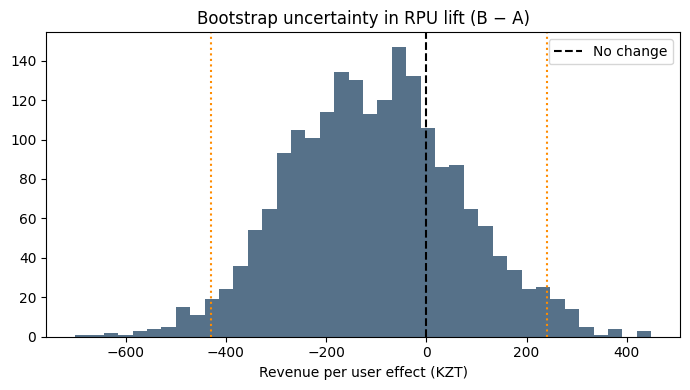

In [7]:
ra=df.loc[df.group.eq('A'),'revenue_kzt'].to_numpy();rb=df.loc[df.group.eq('B'),'revenue_kzt'].to_numpy()
t_stat,p_rpu=stats.ttest_ind(rb,ra,equal_var=False)
rpu_diff=rb.mean()-ra.mean()
rg=np.random.default_rng(SEED);reps=2000;boot=np.empty(reps)
for i in range(reps):
 boot[i]=rg.choice(rb,len(rb),replace=True).mean()-rg.choice(ra,len(ra),replace=True).mean()
ci_rpu=np.quantile(boot,[.025,.975])
print(f'RPU A={ra.mean():,.2f} KZT; B={rb.mean():,.2f} KZT; B−A={rpu_diff:,.2f} KZT')
print(f'Welch test: t={t_stat:.3f}, p={p_rpu:.5f}; bootstrap 95% percentile CI [{ci_rpu[0]:,.2f}, {ci_rpu[1]:,.2f}] KZT')
fig,ax=plt.subplots(figsize=(7,4));ax.hist(boot,bins=40,color='#567189')
ax.axvline(0,color='black',ls='--',label='No change');ax.axvline(ci_rpu[0],color='darkorange',ls=':');ax.axvline(ci_rpu[1],color='darkorange',ls=':')
ax.set_title('Bootstrap uncertainty in RPU lift (B − A)');ax.set_xlabel('Revenue per user effect (KZT)');ax.legend()
fig.tight_layout();plt.savefig(ROOT/'images'/'rpu_bootstrap.png',dpi=160,bbox_inches='tight');plt.show()

**Metric definition:** RPU includes purchasers **and non-purchasers**. Comparing only positive orders answers a different question (AOV). Bootstrap resamples users independently within randomized groups.

## 8. Sensitivity analysis: extreme order values

In [8]:
# Exploratory only: cap order values at a common 99th percentile of positive orders.
cap=orders.revenue_kzt.quantile(.99)
capped=df.assign(revenue_capped=df.revenue_kzt.clip(upper=cap))
cap_rpu=capped.groupby('group').revenue_capped.mean()
print(f'Global buyer-level P99 cap: {cap:,.0f} KZT')
print('Original RPU B−A:',round(rpu_diff,2),'KZT')
print('P99 capped RPU B−A:',round(cap_rpu['B']-cap_rpu['A'],2),'KZT')

Global buyer-level P99 cap: 69,605 KZT
Original RPU B−A: -105.57 KZT
P99 capped RPU B−A: -57.43 KZT


## 9. Cumulative metrics across experiment dates

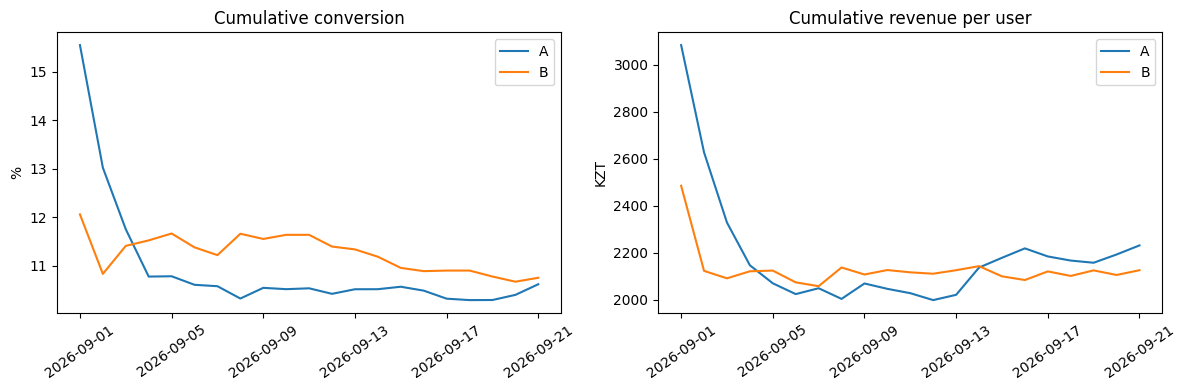

In [9]:
daily=df.groupby(['date','group']).agg(users=('user_id','size'),buyers=('converted','sum'),revenue=('revenue_kzt','sum')).reset_index().sort_values('date')
for c in ['users','buyers','revenue']:
 daily[f'cum_{c}']=daily.groupby('group')[c].cumsum()
daily['cumulative_conversion']=daily.cum_buyers/daily.cum_users
fig,ax=plt.subplots(1,2,figsize=(12,4))
for g,d in daily.groupby('group'):
 ax[0].plot(d.date,d.cumulative_conversion*100,label=g)
 ax[1].plot(d.date,d.cum_revenue/d.cum_users,label=g)
ax[0].set_title('Cumulative conversion');ax[0].set_ylabel('%')
ax[1].set_title('Cumulative revenue per user');ax[1].set_ylabel('KZT')
for a_ in ax:a_.legend();a_.tick_params(axis='x',rotation=35)
fig.tight_layout();plt.savefig(ROOT/'images'/'cumulative_metrics.png',dpi=160,bbox_inches='tight');plt.show()

**Note:** These plots are descriptive, not a justification for repeated significance checks or early stopping. Sequential decision-making requires a pre-specified sequential testing method.

## 10. Segment exploration and multiplicity

In [10]:
for col in ['device','segment','country']:
 pivot=df.groupby([col,'group']).converted.agg(['mean','size']).reset_index()
 print('SEGMENT:',col);display(pivot)
print('Warning: subgroup analyses are exploratory. Do not interpret many unadjusted p-values as confirmed heterogeneous effects.')

SEGMENT: device


,device,group,mean,size
0,desktop,A,0.123957,1678
1,desktop,B,0.116977,1667
2,mobile,A,0.099260,4322
3,mobile,B,0.103854,4333


SEGMENT: segment


,segment,group,mean,size
0,new,A,0.086710,3356
1,new,B,0.088349,3373
2,returning,A,0.130862,2644
3,returning,B,0.132090,2627


SEGMENT: country


,country,group,mean,size
0,KG,A,0.112941,425
1,KG,B,0.125604,414
2,KZ,A,0.106250,4960
3,KZ,B,0.105146,4936
4,UZ,A,0.100813,615
5,UZ,B,0.113846,650


## 11. Minimum detectable effect and power

In [11]:
baseline=.105;absolute_mde=.015;planned_target=baseline+absolute_mde
es=proportion_effectsize(planned_target,baseline)
required=NormalIndPower().solve_power(effect_size=es,alpha=.05,power=.8,alternative='two-sided',ratio=1)
print(f'Assumed baseline: {baseline:.1%}; absolute MDE: {absolute_mde:.1%}; power: 80%; α: 5%')
print(f'Estimated required n/group: {np.ceil(required):,.0f}; observed: {counts.tolist()}')

Assumed baseline: 10.5%; absolute MDE: 1.5%; power: 80%; α: 5%
Estimated required n/group: 6,959; observed: [6000, 6000]


**Planning caveat:** Baseline and MDE are scenario assumptions for a hypothetical future experiment, not evidence of an actual preregistered design. A non-significant result does not establish equivalence.

## 12. Decision memo (data-driven)

In [12]:
outcome='statistically significant' if p_cr<.05 else 'not statistically significant'
action='Consider a controlled rollout, subject to RPU guardrails and experiment QA.' if p_cr<.05 and ci_abs[0]>0 else 'Do not claim an uplift; run a sufficiently powered follow-up or retain control.'
report=f"""### Executive summary — ShopNext simulated checkout experiment
- **Dataset:** {len(df):,} unique randomized users from a synthetic practice dataset.
- **Primary KPI:** A {a.conversion_rate:.2%}, B {b.conversion_rate:.2%}; **B − A = {cr_diff*100:+.2f} percentage points** ({relative_lift:+.1%} relative).
- **Conversion inference:** two-sided z-test p = {p_cr:.4g}, 95% effect CI **[{ci_abs[0]*100:+.2f}, {ci_abs[1]*100:+.2f}] pp**; result is {outcome} at α=0.05.
- **Revenue guardrail:** RPU A {ra.mean():,.0f} KZT vs B {rb.mean():,.0f} KZT; bootstrap effect CI [{ci_rpu[0]:,.0f}, {ci_rpu[1]:,.0f}] KZT; Welch p = {p_rpu:.4g}.
- **Instrumentation check:** group sizes {counts[0]:,}/{counts[1]:,}; SRM test p = {srm_p:.4g}.
- **Decision:** {action}
- **Limitations:** synthetic observations, unknown representativeness, no pre-registration or guardrail margins, sensitivity to high-value orders; subgroup findings are exploratory.
"""
display(Markdown(report))

### Executive summary — ShopNext simulated checkout experiment
- **Dataset:** 12,000 unique randomized users from a synthetic practice dataset.
- **Primary KPI:** A 10.62%, B 10.75%; **B − A = +0.13 percentage points** (+1.3% relative).
- **Conversion inference:** two-sided z-test p = 0.8131, 95% effect CI **[-0.97, +1.24] pp**; result is not statistically significant at α=0.05.
- **Revenue guardrail:** RPU A 2,230 KZT vs B 2,125 KZT; bootstrap effect CI [-429, 242] KZT; Welch p = 0.5299.
- **Instrumentation check:** group sizes 6,000/6,000; SRM test p = 1.
- **Decision:** Do not claim an uplift; run a sufficiently powered follow-up or retain control.
- **Limitations:** synthetic observations, unknown representativeness, no pre-registration or guardrail margins, sensitivity to high-value orders; subgroup findings are exploratory.
